# Наивный Байес: четыре варианта и зачем каждый придуман

> Это **продолжение** основного ноутбука про Naive Bayes (он остаётся без изменений). Здесь — только про варианты модели.

Наивный Байес — это не один алгоритм, а **шаблон**. «Наивная» часть везде одна и та же:

$$\hat y = \arg\max_y \Big[\log P(y) + \sum_j \log P(x_j \mid y)\Big]$$

Варианты отличаются **только одним**: какое распределение $P(x_j\mid y)$ мы предполагаем для одного признака.

| Вариант | Предположение о признаке | Типичные данные | Что оценивается |
|---|---|---|---|
| `GaussianNB` | непрерывное, «колокол» | измерения: рост, длина лепестка, показания датчиков | среднее и дисперсия на (класс, признак) |
| `MultinomialNB` | счётчик: сколько раз что-то произошло | частоты слов, число покупок, «сколько раз» | доля каждого признака в «общем счёте» класса |
| `BernoulliNB` | бинарный флаг: было / не было | наличие слова, симптом есть/нет | вероятность флага = 1 (и **явно** вероятность = 0) |
| `ComplementNB` | как Multinomial, но по «дополнению» класса | тексты с **несбалансированными** классами | доли признаков во *всех остальных* классах |

Для каждого варианта ниже: **сценарий, ради которого он придуман → эксперимент → что происходит, если взять «не тот» вариант.** В конце — общая матрица «данные × вариант».

Данные для вариантов 2–4 **синтетические** (генерируются по предположениям соответствующей модели, чтобы механизм был виден чисто). Реальные данные (20 Newsgroups) — в разделе 7.

In [19]:
import warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import norm

from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB, ComplementNB, CategoricalNB
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OrdinalEncoder, OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score, StratifiedKFold, train_test_split
from sklearn.metrics import accuracy_score, f1_score, recall_score, confusion_matrix
from sklearn.datasets import load_iris, load_digits

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold"})
RS = 42
CV = StratifiedKFold(5, shuffle=True, random_state=RS)

# у каждого варианта свой цвет, он сохраняется во всех графиках
COL = {"GaussianNB": "#E4572E", "MultinomialNB": "#2E86AB", "BernoulliNB": "#6A994E", "ComplementNB": "#8D6A9F"}

def four(**kw):
    return {"GaussianNB": GaussianNB(), "MultinomialNB": MultinomialNB(), "BernoulliNB": BernoulliNB(), "ComplementNB": ComplementNB()}

def cv_scores(X, y, models=None, scoring="accuracy"):
    models = models or four()
    return {n: cross_val_score(m, X, y, cv=CV, scoring=scoring).mean() for n, m in models.items()}

def bar(ax, scores, title, ylabel="accuracy", ylim=None):
    names = list(scores); vals = [scores[n] for n in names]
    ax.bar(names, vals, color=[COL.get(n, "#999") for n in names])
    for i, v in enumerate(vals): ax.text(i, v + 0.005, f"{v:.3f}", ha="center", fontsize=10)
    ax.set_title(title); ax.set_ylabel(ylabel); ax.tick_params(axis="x", rotation=15)
    if ylim: ax.set_ylim(*ylim)

## 1. `GaussianNB` — непрерывные признаки

**Для чего придуман.** Признаки — вещественные измерения (длина, вес, температура). Самая простая модель «как выглядит класс»: для каждого признака и каждого класса запоминаем **среднее и стандартное отклонение**, и считаем, что значения распределены нормально.

Пример — классический `iris` (длины и ширины лепестков/чашелистиков трёх видов ирисов). Посмотрим, что модель на самом деле выучила: это просто набор «колоколов».

Средние (строки — классы, столбцы — признаки):


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
setosa,5.01,3.43,1.46,0.25
versicolor,5.94,2.77,4.26,1.33
virginica,6.59,2.97,5.55,2.03


Стандартные отклонения:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
setosa,0.35,0.38,0.17,0.10
versicolor,0.51,0.31,0.47,0.20
virginica,0.63,0.32,0.55,0.27


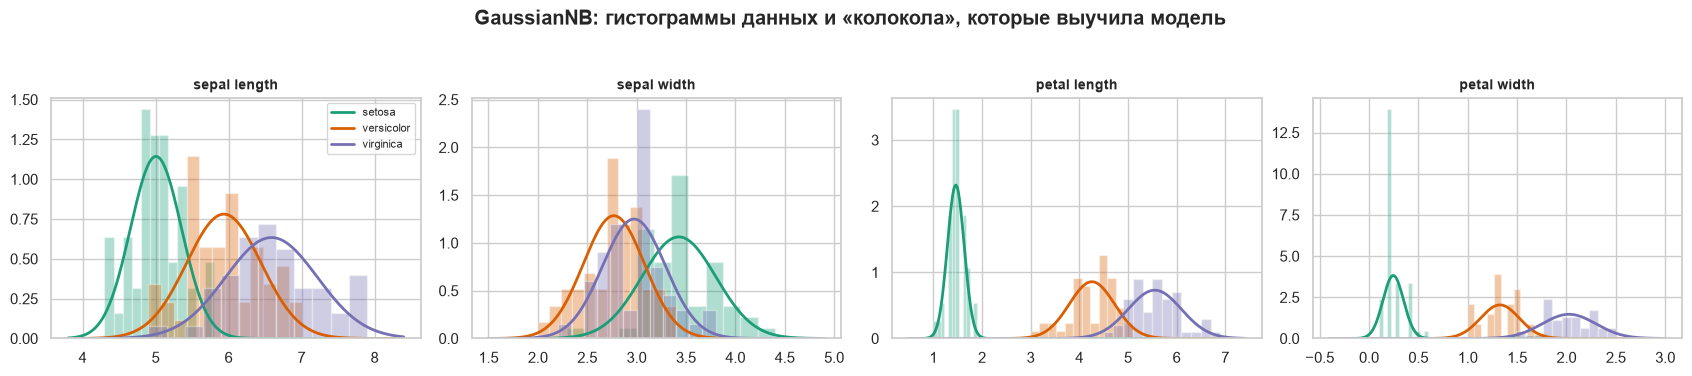

accuracy (5-fold CV):  0.947


In [20]:
iris = load_iris()
X, y = iris.data, iris.target
gnb = GaussianNB().fit(X, y)

# вся «модель» — две таблицы: средние и стандартные отклонения
print("Средние (строки — классы, столбцы — признаки):")
display(pd.DataFrame(gnb.theta_, index=iris.target_names, columns=iris.feature_names).round(2))
print("Стандартные отклонения:")
display(pd.DataFrame(np.sqrt(gnb.var_), index=iris.target_names, columns=iris.feature_names).round(2))

fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
palette = ["#1b9e77", "#d95f02", "#7570b3"]
for j, ax in enumerate(axes):
    xs = np.linspace(X[:, j].min() - 0.5, X[:, j].max() + 0.5, 300)
    for c in range(3):
        ax.hist(X[y == c, j], bins=12, density=True, alpha=0.35, color=palette[c])
        ax.plot(xs, norm.pdf(xs, gnb.theta_[c, j], np.sqrt(gnb.var_[c, j])), color=palette[c], lw=2,
                label=iris.target_names[c] if j == 0 else None)
    ax.set_title(iris.feature_names[j].replace(" (cm)", ""), fontsize=10)
axes[0].legend(fontsize=8)
plt.suptitle("GaussianNB: гистограммы данных и «колокола», которые выучила модель", y=1.04, fontweight="bold")
plt.tight_layout(); plt.show()
print("accuracy (5-fold CV): ", round(cross_val_score(GaussianNB(), X, y, cv=CV).mean(), 3))

Колокола хорошо ложатся на гистограммы, особенно для лепестков (`petal`), где виды почти не пересекаются. Поэтому `GaussianNB` здесь работает отлично.

**Когда это ломается** — когда признак **не похож на колокол**: счётчики с кучей нулей, бинарные флаги, сильно скошенные величины. Именно для этих случаев придуманы остальные варианты. Дальше — по очереди.

## 2. `MultinomialNB` — счётчики

**Для чего придуман.** Тексты. Документ — «мешок слов»: вектор, где $x_j$ = сколько раз слово $j$ встретилось. Генеративная история такая: автор $L$ раз вытягивает слово из «мешка» своей темы, и вероятность слова $j$ в теме $y$ равна $\theta_{jy}$. Тогда

$$P(x\mid y) \propto \prod_j \theta_{jy}^{x_j},\qquad \theta_{jy} = \frac{N_{jy}+\alpha}{N_y+\alpha V}$$

где $N_{jy}$ — сколько раз слово $j$ встретилось во всех документах класса $y$, $N_y$ — общее число слов класса, $V$ — размер словаря, $\alpha$ — сглаживание.

**Эксперимент.** Генерируем корпус: 3 темы, словарь 1000 слов, документы **разной длины** (от нескольких слов до сотен — как в жизни).

In [21]:
def gen_counts(n_per_class, V=1000, len_median=40, sharp=0.1, sigma=0.9, seed=RS):
    # Корпус «мешков слов»: у каждой темы своё распределение слов; длины документов — логнормальные
    r = np.random.RandomState(seed)
    base = r.dirichlet(np.full(V, 0.3))                                  # общая лексика
    theta = [(1 - sharp) * base + sharp * r.dirichlet(np.full(V, 0.05)) for _ in n_per_class]  # + «свои» слова темы
    X, y = [], []
    for c, n in enumerate(n_per_class):
        for _ in range(n):
            L = max(5, int(r.lognormal(np.log(len_median), sigma)))
            X.append(r.multinomial(L, theta[c])); y.append(c)
    return np.array(X), np.array(y)

Xc, yc = gen_counts([400, 400, 400])
lens = Xc.sum(1)
print(f"документов: {len(yc)}, словарь: {Xc.shape[1]}, доля нулей в матрице: {(Xc == 0).mean():.1%}")
print(f"длина документа: медиана {np.median(lens):.0f}, от {lens.min()} до {lens.max()} слов")

документов: 1200, словарь: 1000, доля нулей в матрице: 95.2%
длина документа: медиана 40, от 5 до 703 слов


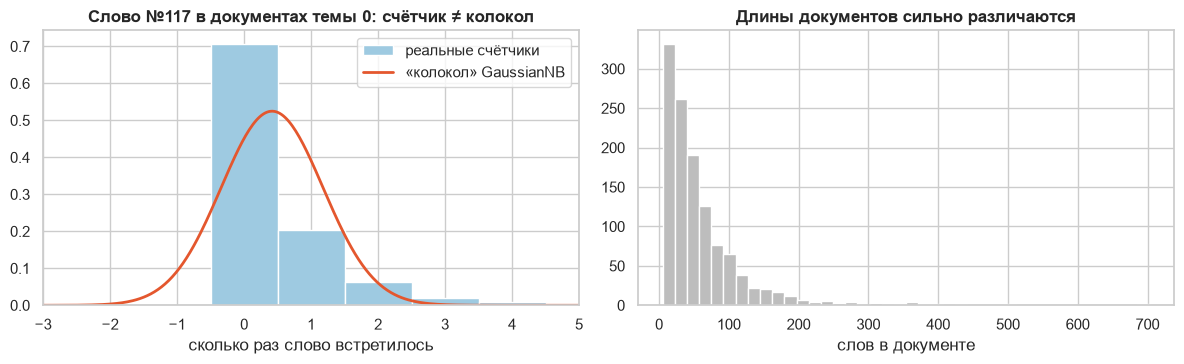

доля документов, где слова нет вообще: 71%; колокол отдаёт ненулевую плотность отрицательным значениям


In [22]:
# Как выглядит ОДИН признак (слово) внутри одного класса?
j = int(np.argmax(MultinomialNB().fit(Xc, yc).feature_log_prob_[0] - MultinomialNB().fit(Xc, yc).feature_log_prob_[1:].mean(0)))
vals = Xc[yc == 0, j]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
vmax = vals.max()
axes[0].hist(vals, bins=np.arange(vmax + 2) - 0.5, density=True, color="#9ecae1", edgecolor="w", label="реальные счётчики")
xs = np.linspace(-3, vmax + 1, 300)
axes[0].plot(xs, norm.pdf(xs, vals.mean(), vals.std()), color=COL["GaussianNB"], lw=2, label="«колокол» GaussianNB")
axes[0].set_title(f"Слово №{j} в документах темы 0: счётчик ≠ колокол"); axes[0].set_xlabel("сколько раз слово встретилось"); axes[0].legend()
axes[0].set_xlim(-3, min(vmax + 1, 25))
axes[1].hist(lens, bins=40, color="#bdbdbd"); axes[1].set_title("Длины документов сильно различаются"); axes[1].set_xlabel("слов в документе")
plt.tight_layout(); plt.show()
print(f"доля документов, где слова нет вообще: {(vals == 0).mean():.0%}; колокол отдаёт ненулевую плотность отрицательным значениям")

Счётчик слова — дискретный, с огромной долей нулей и «хвостом»; нормальное распределение его описывает плохо (даже «разрешает» отрицательные значения). К тому же длинный документ даёт большие счётчики *по всем словам сразу* — Гауссову модели это мешает, а Мультиномиальная учитывает длину естественным образом (через сумму $\sum x_j \log\theta_{jy}$).

Сравним все четыре варианта на этих данных:

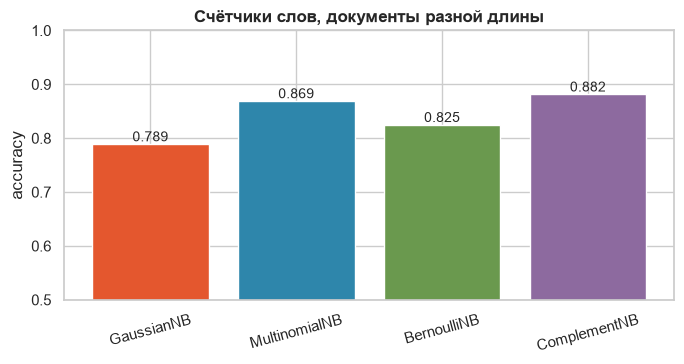

In [23]:
sc = cv_scores(Xc, yc)
fig, ax = plt.subplots(figsize=(7, 3.8))
bar(ax, sc, "Счётчики слов, документы разной длины", ylim=(0.5, 1.0))
plt.tight_layout(); plt.show()

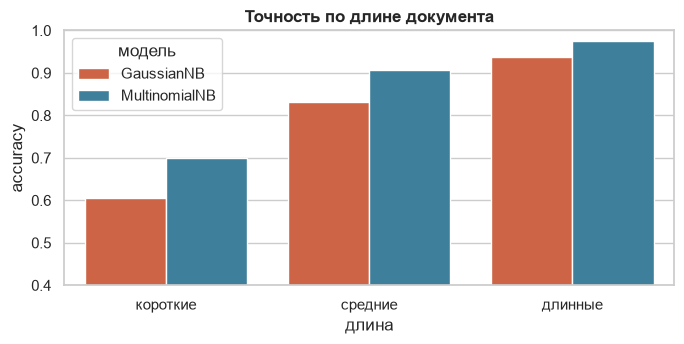

In [24]:
# Где именно GaussianNB проигрывает? Разобьём тестовые документы на «короткие / средние / длинные»
Xtr, Xte, ytr, yte = train_test_split(Xc, yc, test_size=0.4, random_state=RS, stratify=yc)
L = Xte.sum(1); bins = pd.qcut(L, 3, labels=["короткие", "средние", "длинные"])
rows = []
for name in ["GaussianNB", "MultinomialNB"]:
    pred = four()[name].fit(Xtr, ytr).predict(Xte)
    for b in ["короткие", "средние", "длинные"]:
        m = np.asarray(bins == b); rows.append(dict(модель=name, длина=b, accuracy=(pred[m] == yte[m]).mean()))
d = pd.DataFrame(rows)
plt.figure(figsize=(7, 3.6))
sns.barplot(data=d, x="длина", y="accuracy", hue="модель", palette=COL)
plt.ylim(0.4, 1.0); plt.title("Точность по длине документа"); plt.tight_layout(); plt.show()

In [25]:
# Проверим формулу: feature_log_prob_ действительно = log((N_jy + alpha) / (N_y + alpha*V))
alpha = 1.0
m = MultinomialNB(alpha=alpha).fit(Xc, yc)
manual = np.array([np.log((Xc[yc == c].sum(0) + alpha) / (Xc[yc == c].sum() + alpha * Xc.shape[1])) for c in np.unique(yc)])
print("feature_log_prob_ совпадает с ручной формулой:", np.allclose(m.feature_log_prob_, manual))

feature_log_prob_ совпадает с ручной формулой: True


**Ещё одно ограничение (важно знать): `MultinomialNB` принимает только неотрицательные признаки.** Счётчики и TF-IDF — можно (дробные значения тоже ок), а вот стандартизованные данные (`StandardScaler`) — нет:

In [26]:
try:
    MultinomialNB().fit(StandardScaler().fit_transform(Xc), yc)
except ValueError as e:
    print("ValueError:", e)
print("TF-IDF (дробные неотрицательные значения) — работает:")
from sklearn.feature_extraction.text import TfidfTransformer
Xt = TfidfTransformer().fit_transform(Xc)
print("accuracy MultinomialNB на TF-IDF:", round(cross_val_score(MultinomialNB(), Xt, yc, cv=CV).mean(), 3))

ValueError: Negative values in data passed to MultinomialNB (input X).
TF-IDF (дробные неотрицательные значения) — работает:
accuracy MultinomialNB на TF-IDF: 0.868


**Бонус: пиксели.** В основном ноутбуке `digits` (картинки 8×8, значения 0–16) давал `GaussianNB` ≈ 0.85. Если смотреть на яркость пикселя как на «сколько чернил попало в клетку», то это тоже похоже на счётчики. Проверим:

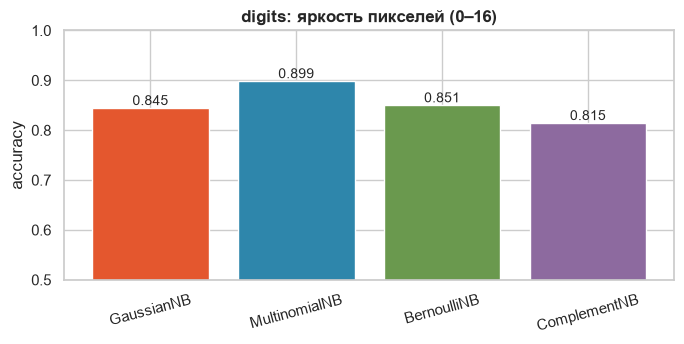

In [27]:
Xd, yd = load_digits(return_X_y=True)
sc_d = cv_scores(Xd, yd)
fig, ax = plt.subplots(figsize=(7, 3.6))
bar(ax, sc_d, "digits: яркость пикселей (0–16)", ylim=(0.5, 1.0)); plt.tight_layout(); plt.show()

Пиксельные интенсивности — неотрицательные «почти счётчики», и `MultinomialNB` здесь заметно лучше `GaussianNB` (≈0.90 против ≈0.85): колокол плохо описывает пиксель, который чаще всего равен 0 или близок к максимуму. То есть пиксели — не обязательно пример для `GaussianNB`: выбор варианта зависит от того, как *распределён* признак, а не от того, что это «число». (Для сравнения: Logistic Regression в основном ноутбуке давала на `digits` ≈0.97 — потолок NB ограничен независимостью пикселей.)

## 3. `BernoulliNB` — бинарные флаги

**Для чего придуман.** Признак — «есть / нет»: есть ли слово в документе, есть ли симптом у пациента, купил ли клиент товар. Каждый признак — отдельная монетка с вероятностью $p_{jy}=P(x_j=1\mid y)$:

$$P(x\mid y)=\prod_j p_{jy}^{x_j}\,(1-p_{jy})^{1-x_j}$$

**Главное отличие от Multinomial:** Бернулли **явно учитывает отсутствие** признака (множитель $1-p_{jy}$). Мультиномиальный на отсутствующий признак просто не смотрит (там $x_j=0$ даёт множитель 1). Если «чего-то нет» — это важный сигнал (например, у больного гриппом *нет* аллергической сыпи), то Бернулли ловит его, а Мультиномиальный — нет.

**Эксперимент 1: отсутствие признака несёт информацию.** 40 бинарных флагов, у 8 из них вероятности зависят от класса (одни чаще, другие реже).

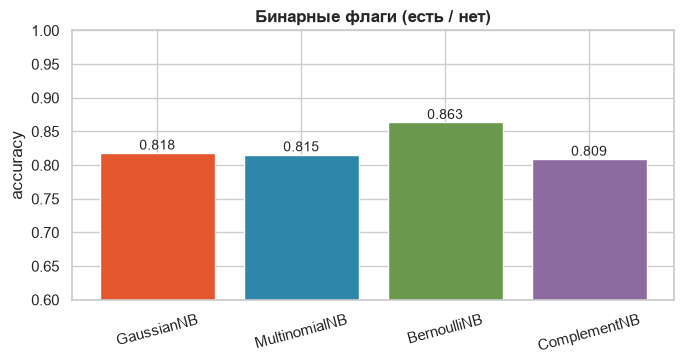

In [28]:
def gen_binary(n=2000, d=40, k=8, seed=RS):
    r = np.random.RandomState(seed)
    p0 = r.uniform(0.05, 0.6, d); p1 = p0.copy()
    idx = r.choice(d, k, replace=False)
    p1[idx] = np.clip(p0[idx] * r.choice([0.25, 2.5], k), 0.01, 0.95)    # у k признаков вероятность зависит от класса
    y = r.randint(0, 2, n)
    X = (r.rand(n, d) < np.where(y[:, None] == 1, p1, p0)).astype(int)
    return X, y

Xb, yb = gen_binary()
sc_b = cv_scores(Xb, yb)
fig, ax = plt.subplots(figsize=(7, 3.8))
bar(ax, sc_b, "Бинарные флаги (есть / нет)", ylim=(0.6, 1.0)); plt.tight_layout(); plt.show()

In [29]:
# Откуда берётся преимущество: разложим «доказательство в пользу класса 1» на вклад ПРИСУТСТВУЮЩИХ и ОТСУТСТВУЮЩИХ признаков
bn = BernoulliNB(alpha=1).fit(Xb, yb)
lp = bn.feature_log_prob_                 # log p_jy
lq = np.log1p(-np.exp(lp))                # log (1 - p_jy)
llr_present = Xb @ (lp[1] - lp[0])                 # сумма по признакам, которые есть
llr_absent  = (1 - Xb) @ (lq[1] - lq[0])           # сумма по признакам, которых нет
print(f"средний |вклад| присутствующих признаков: {np.abs(llr_present).mean():.2f}")
print(f"средний |вклад| ОТСУТСТВУЮЩИХ признаков:  {np.abs(llr_absent).mean():.2f}   <- эту часть MultinomialNB не использует")

средний |вклад| присутствующих признаков: 1.53
средний |вклад| ОТСУТСТВУЮЩИХ признаков:  1.49   <- эту часть MultinomialNB не использует


Примерно **половина** всего «доказательства» берётся из отсутствующих признаков — и именно её теряет `MultinomialNB`. Отсюда разрыв на графике выше (≈0.86 у `BernoulliNB` против ≈0.82 у остальных). Разрыв умеренный, потому что в данных у всех признаков есть и «присутствующая» информация; он растёт, когда сигнал в основном в отсутствии.

**Эксперимент 2: «всплески» слов (burstiness).** В реальных текстах, если слово уже встретилось, оно часто повторяется много раз (название продукта, имя). Мультиномиальная модель считает каждое повторение *независимым* свидетельством и сильно перевзвешивает такие слова. Бернулли смотрит только на «есть / нет».

Возьмём те же бинарные данные и превратим их в счётчики: если признак есть, то он повторяется $1+\text{Geom}$ раз (с хвостом), независимо от класса.

средний счётчик среди присутствующих слов: 6.6  максимум: 62


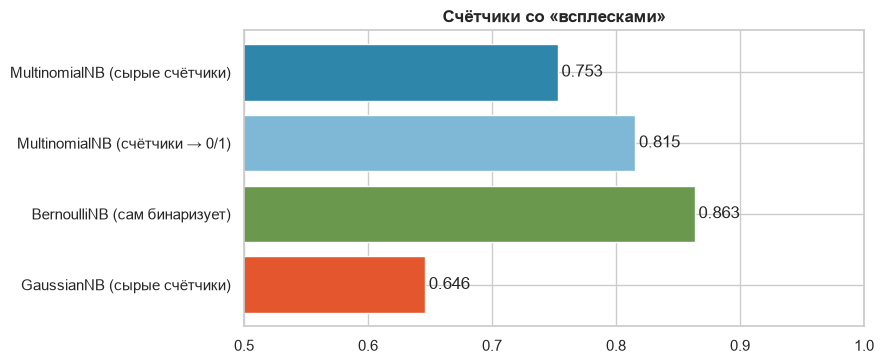

In [30]:
r = np.random.RandomState(RS)
burst = Xb * (1 + r.geometric(0.15, size=Xb.shape) - 1)       # есть -> счётчик с «хвостом» (в среднем ~7 повторов)
print("средний счётчик среди присутствующих слов:", burst[Xb == 1].mean().round(1), " максимум:", burst.max())

variants = {
    "MultinomialNB (сырые счётчики)":            MultinomialNB(),
    "MultinomialNB (счётчики → 0/1)":            make_pipeline(__import__("sklearn.preprocessing", fromlist=["Binarizer"]).Binarizer(), MultinomialNB()),
    "BernoulliNB (сам бинаризует)":              BernoulliNB(),
    "GaussianNB (сырые счётчики)":               GaussianNB(),
}
sc_burst = {k: cross_val_score(m, burst, yb, cv=CV).mean() for k, m in variants.items()}
fig, ax = plt.subplots(figsize=(9, 3.8))
names = list(sc_burst); cols = [COL["MultinomialNB"], "#7fb8d6", COL["BernoulliNB"], COL["GaussianNB"]]
ax.barh(names[::-1], [sc_burst[n] for n in names][::-1], color=cols[::-1])
for i, n in enumerate(names[::-1]): ax.text(sc_burst[n] + 0.003, i, f"{sc_burst[n]:.3f}", va="center")
ax.set_xlim(0.5, 1.0); ax.set_title("Счётчики со «всплесками»"); plt.tight_layout(); plt.show()

Как читать график: сырые счётчики со «всплесками» портят `MultinomialNB` (≈0.75 против ≈0.82 на бинаризованных), а `GaussianNB` — ещё сильнее (≈0.65). `BernoulliNB` (≈0.86) лучше и бинаризованного `MultinomialNB`, потому что дополнительно использует отсутствие признаков.

Практический вывод: если в данных важен сам **факт** наличия (а не частота) и документы короткие или «всплесковые», берите `BernoulliNB` (или `MultinomialNB` на бинаризованных счётчиках — `CountVectorizer(binary=True)`). Если частота действительно информативна (длинные тексты, много повторов по теме) — `MultinomialNB`.

## 4. `ComplementNB` — несбалансированные классы

**Для чего придуман.** Это улучшение `MultinomialNB` для текстов, у которых классы разного размера (3 новостных рубрики — по 1000 статей, а 4-я — 30). Идея (Rennie et al., 2003): вместо «какие слова свойственны *этому* классу» оценивать «какие слова *не* свойственны **всем остальным**», то есть считать $\theta$ по *дополнению* класса. У маленького класса мало своих данных, а у его дополнения — много, поэтому оценки стабильнее, а смещение в пользу крупных классов слабее.

**Эксперимент.** Корпус из 4 тем с размерами 1500 / 300 / 80 / 30 документов. Качество смотрим по **recall каждого класса** и **macro-F1** (одинаково важны все классы): accuracy тут обманчива — достаточно всегда отвечать «самый большой класс».

размеры классов (train): [900 180  48  18]  (test): [600 120  32  12]
accuracy «всегда самый большой класс»: 0.785


,accuracy,macro_F1
MultinomialNB,0.919,0.570
MultinomialNB (без приора),0.899,0.609
ComplementNB,0.910,0.692


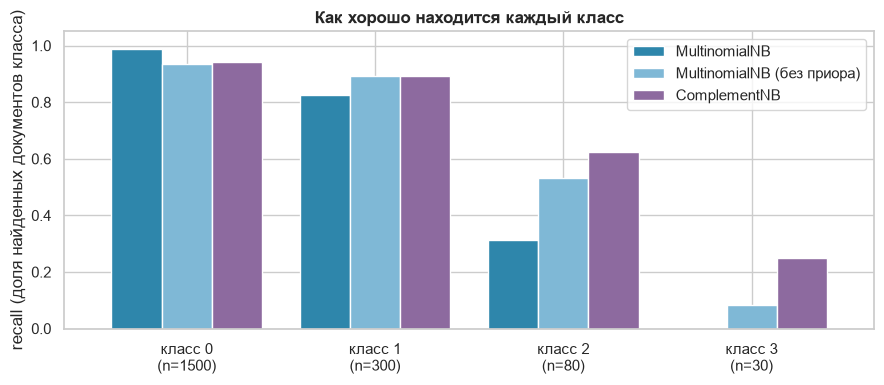

In [31]:
sizes = [1500, 300, 80, 30]
Xi, yi = gen_counts(sizes, sharp=0.1, len_median=40, seed=3)
Xtr, Xte, ytr, yte = train_test_split(Xi, yi, test_size=0.4, stratify=yi, random_state=RS)
print("размеры классов (train):", np.bincount(ytr), " (test):", np.bincount(yte))
print("accuracy «всегда самый большой класс»:", round(np.mean(yte == 0), 3))

cands = {"MultinomialNB": MultinomialNB(),
         "MultinomialNB (без приора)": MultinomialNB(fit_prior=False),
         "ComplementNB": ComplementNB()}
preds = {k: m.fit(Xtr, ytr).predict(Xte) for k, m in cands.items()}
summary = pd.DataFrame({k: dict(accuracy=accuracy_score(yte, p), macro_F1=f1_score(yte, p, average="macro")) for k, p in preds.items()}).T.round(3)
display(summary)

rec = pd.DataFrame({k: recall_score(yte, p, average=None) for k, p in preds.items()},
                   index=[f"класс {c}\n(n={s})" for c, s in enumerate(sizes)])
rec_cols = {"MultinomialNB": COL["MultinomialNB"], "MultinomialNB (без приора)": "#7fb8d6", "ComplementNB": COL["ComplementNB"]}
ax = rec.plot.bar(figsize=(9, 4), color=[rec_cols[c] for c in rec.columns], rot=0, width=0.8)
ax.set_ylabel("recall (доля найденных документов класса)"); ax.set_title("Как хорошо находится каждый класс"); ax.set_ylim(0, 1.05)
plt.tight_layout(); plt.show()

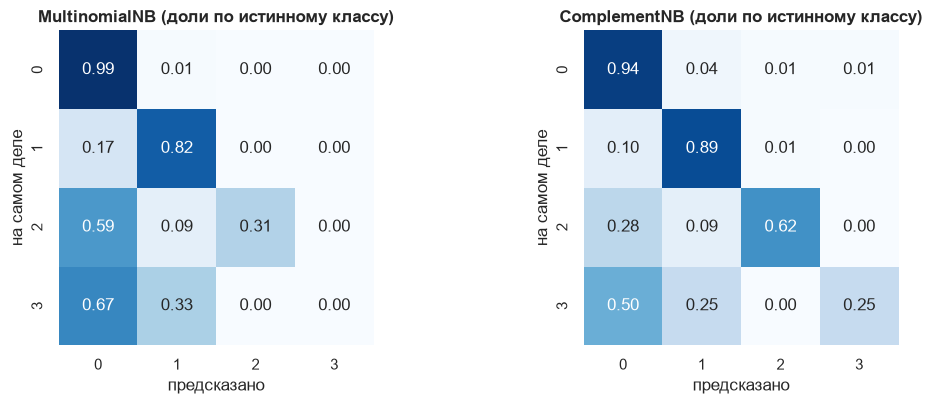

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, name in zip(axes, ["MultinomialNB", "ComplementNB"]):
    cm = confusion_matrix(yte, preds[name], normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", cbar=False, vmin=0, vmax=1, ax=ax, square=True)
    ax.set_title(name + " (доли по истинному классу)"); ax.set_xlabel("предсказано"); ax.set_ylabel("на самом деле")
plt.tight_layout(); plt.show()

`MultinomialNB` почти всегда отвечает «крупный класс»: из 12 документов самого маленького класса ни один не найден (recall = 0), а у третьего класса recall ≈0.3. Accuracy при этом высокая (≈0.92 при 0.79 у «всегда самый большой класс»), а macro-F1 всего ≈0.57 — именно она показывает проблему. Отключение приора (`fit_prior=False`) немного помогает, но не решает проблему — перекос сидит и в оценках $\theta$. `ComplementNB` заметно лучше находит редкие классы: macro-F1 ≈0.69 против ≈0.57, у третьего класса recall вырастает до ≈0.6. Платой стала чуть более низкая accuracy (≈0.91 против ≈0.92) — это нормальная цена. Но проблема не исчезла полностью: самый маленький класс всё ещё находится плохо (recall ≈0.25 на 12 документах — оценка шумная).

**Честная оговорка:** на сбалансированных данных `ComplementNB` и `MultinomialNB` дают близкие результаты (см. матрицу в разделе 5) — «чудо» проявляется именно при дисбалансе.

## 5. Матрица «тип данных × вариант»

Четыре сценария (по одному на вариант), все четыре модели на каждом. Метрика везде — **macro-F1** (в сбалансированных сценариях она почти совпадает с accuracy, а в несбалансированном — честнее). Если ваш вариант «родной» для данных, он должен быть в числе лучших — это и есть ответ на вопрос «зачем столько вариантов».

Для непрерывных данных `Multinomial/Bernoulli/Complement` требуют неотрицательных значений, поэтому им подаём данные после `MinMaxScaler` (а Бернулли дополнительно бинаризует по порогу 0.5).

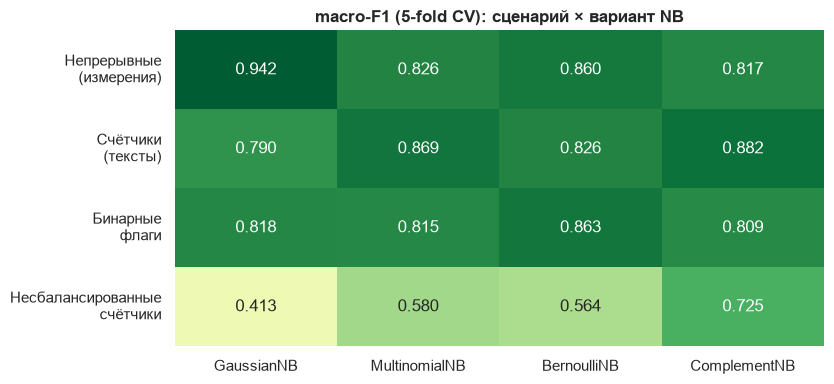

In [33]:
def gen_continuous(n=900, d=8, seed=RS):
    r = np.random.RandomState(seed)
    y = r.randint(0, 3, n)
    means = r.normal(0, 1.2, (3, d)); sds = r.uniform(0.7, 1.6, (3, d))
    return means[y] + r.randn(n, d) * sds[y], y

Xcont, ycont = gen_continuous()
scenarios = {
    "Непрерывные\n(измерения)":       (Xcont, ycont, "cont"),
    "Счётчики\n(тексты)":             (Xc, yc, "raw"),
    "Бинарные\nфлаги":                (Xb, yb, "raw"),
    "Несбалансированные\nсчётчики":   (Xi, yi, "raw"),
}

def models_for(kind):
    if kind == "cont":
        return {"GaussianNB": GaussianNB(),
                "MultinomialNB": make_pipeline(MinMaxScaler(), MultinomialNB()),
                "BernoulliNB": make_pipeline(MinMaxScaler(), BernoulliNB(binarize=0.5)),
                "ComplementNB": make_pipeline(MinMaxScaler(), ComplementNB())}
    return four()

mat = pd.DataFrame({sname: cv_scores(X, y, models_for(kind), scoring="f1_macro") for sname, (X, y, kind) in scenarios.items()}).T[list(COL)]
fig, ax = plt.subplots(figsize=(8.5, 4))
sns.heatmap(mat, annot=True, fmt=".3f", cmap="YlGn", vmin=0.3, vmax=1, cbar=False, ax=ax)
ax.set_title("macro-F1 (5-fold CV): сценарий × вариант NB"); ax.set_ylabel(""); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

## 6. Бонус: `CategoricalNB` — категории

В основном ноутбуке в таблице вариантов был и пятый — `CategoricalNB`. Он нужен для **дискретных категориальных** признаков (город, тип устройства, тариф), когда у признака есть несколько значений без порядка. Для каждой категории хранится своя вероятность в каждом классе.

Типичная ловушка: закодировать категории числами 0, 1, 2… и подать в `GaussianNB` — модель решит, что «город 3» больше «города 1» и между ними есть «середина».

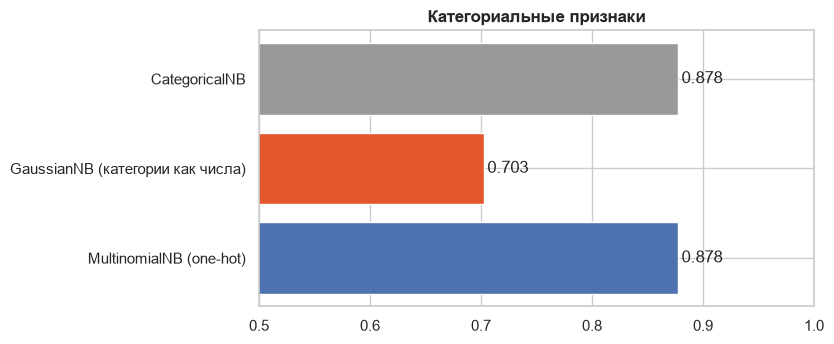

In [34]:
r = np.random.RandomState(RS)
n = 3000
yk = r.randint(0, 2, n)
def cat(p0, p1): return np.array([r.choice(len(p0), p=(p1 if c else p0)) for c in yk])
city   = cat([.30, .05, .30, .05, .30], [.05, .45, .05, .40, .05])      # 5 городов: профили — НЕ монотонны по номеру
device = cat([.50, .30, .20],          [.20, .30, .50])
plan   = cat([.25, .25, .25, .25],     [.40, .10, .40, .10])
Xk = np.c_[city, device, plan]

models_k = {
    "CategoricalNB":                    CategoricalNB(),
    "GaussianNB (категории как числа)": GaussianNB(),
    "MultinomialNB (one-hot)":          make_pipeline(OneHotEncoder(), MultinomialNB()),
}
sc_k = {k: cross_val_score(m, Xk, yk, cv=CV).mean() for k, m in models_k.items()}
fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.barh(list(sc_k)[::-1], list(sc_k.values())[::-1], color=["#999", COL["GaussianNB"], "#4c72b0"][::-1])
for i, v in enumerate(list(sc_k.values())[::-1]): ax.text(v + 0.003, i, f"{v:.3f}", va="center")
ax.set_xlim(0.5, 1); ax.set_title("Категориальные признаки"); plt.tight_layout(); plt.show()

`CategoricalNB` и `MultinomialNB` на one-hot дают почти одинаковый результат (это по сути одна и та же модель), но `CategoricalNB` удобнее: не нужен one-hot, на вход идут коды категорий. А `GaussianNB` на «числовых кодах» заметно хуже (≈0.70): он видит порядок и расстояния там, где их нет.

## 7. Проверка на реальных текстах (20 Newsgroups)

Те же идеи на настоящем корпусе (4 категории из книги). Нужен интернет для первой загрузки (~14 МБ); **если сети нет, ячейка просто сообщит об этом и пропустит раздел**.

1. Частоты слов (`CountVectorizer`, 5000 слов): все четыре варианта.
2. Искусственный дисбаланс: оставляем в обучении 100% / 30% / 10% / 5% документов по классам, а тест не трогаем: `MultinomialNB` против `ComplementNB`.

In [35]:
from sklearn.feature_extraction.text import CountVectorizer
cats = ["talk.religion.misc", "soc.religion.christian", "sci.space", "comp.graphics"]
try:
    from sklearn.datasets import fetch_20newsgroups
    kw = dict(categories=cats, remove=("headers", "footers", "quotes"), random_state=RS)
    tr, te = fetch_20newsgroups(subset="train", **kw), fetch_20newsgroups(subset="test", **kw)
    REAL = True
except Exception as e:
    REAL = False
    print("Нет доступа к 20 Newsgroups (", type(e).__name__, ") — раздел пропущен. Запустите ноутбук с интернетом.")

if REAL:
    cvz = CountVectorizer(max_features=5000, stop_words="english")
    Xtr_r = cvz.fit_transform(tr.data); Xte_r = cvz.transform(te.data)
    ytr_r, yte_r = tr.target, te.target
    rows = {}
    for name, m in four().items():
        A, B = (Xtr_r.toarray(), Xte_r.toarray()) if name == "GaussianNB" else (Xtr_r, Xte_r)   # GaussianNB не принимает разреженные
        p = m.fit(A, ytr_r).predict(B)
        rows[name] = dict(accuracy=accuracy_score(yte_r, p), macro_F1=f1_score(yte_r, p, average="macro"))
    print("Частоты слов, обучение на всём train:")
    display(pd.DataFrame(rows).T.round(3))

Частоты слов, обучение на всём train:


,accuracy,macro_F1
GaussianNB,0.680,0.672
MultinomialNB,0.788,0.764
BernoulliNB,0.644,0.618
ComplementNB,0.787,0.734


In [36]:
if REAL:
    rng = np.random.RandomState(RS)
    keep_frac = [1.0, 0.3, 0.1, 0.05]
    idx = np.concatenate([rng.choice(np.where(ytr_r == c)[0], max(5, int(f * (ytr_r == c).sum())), replace=False)
                          for c, f in enumerate(keep_frac)])
    Xi_r, yi_r = Xtr_r[idx], ytr_r[idx]
    print("классы в обучении после прореживания:", np.bincount(yi_r))
    out = {}
    for name, m in {"MultinomialNB": MultinomialNB(), "ComplementNB": ComplementNB()}.items():
        p = m.fit(Xi_r, yi_r).predict(Xte_r)
        out[name] = dict(accuracy=accuracy_score(yte_r, p), macro_F1=f1_score(yte_r, p, average="macro"),
                         **{f"recall {cats[c].split('.')[-1]}": r_ for c, r_ in enumerate(recall_score(yte_r, p, average=None))})
    display(pd.DataFrame(out).T.round(3))

классы в обучении после прореживания: [584 177  59  18]


,accuracy,macro_F1,recall misc,recall christian,recall space,recall graphics
MultinomialNB,0.723,0.620,0.959,0.754,0.882,0.056
ComplementNB,0.738,0.631,0.949,0.820,0.882,0.056


## 8. Шпаргалка: какой вариант выбрать

| Если признаки… | Берите | Почему | Типичная ошибка |
|---|---|---|---|
| вещественные измерения | `GaussianNB` | оценивает среднее и дисперсию; быстро и просто | подавать счётчики/флаги или сильно скошенные величины без преобразования |
| счётчики (частоты слов, число событий), документы разной длины | `MultinomialNB` | модель «мешка слов», естественно учитывает длину | подавать отрицательные значения (`StandardScaler`) — будет `ValueError` |
| бинарные флаги, короткие тексты, «всплесковые» слова | `BernoulliNB` | явно использует *отсутствие* признака, не раздувает повторы | ждать, что он «учтёт частоту» — он видит только 0/1 |
| счётчики + сильный дисбаланс классов | `ComplementNB` | оценки по дополнению устойчивее для редких классов | брать по умолчанию «на всякий случай»: на сбалансированных данных выигрыша нет |
| категории без порядка (город, тариф) | `CategoricalNB` | своя вероятность для каждой категории | кодировать категории числами и подавать в `GaussianNB` |

Общее для всех: допущение независимости признаков и склонность к переуверенным вероятностям (см. основной ноутбук, разделы 3–4). Варианты меняют только вид $P(x_j\mid y)$.

### Источники
- scikit-learn: [Naive Bayes — User Guide](https://scikit-learn.org/stable/modules/naive_bayes.html) (описания всех пяти вариантов и формулы)
- McCallum, Nigam (1998). [A Comparison of Event Models for Naive Bayes Text Classification](https://www.cs.tufts.edu/~nr/cs257/archive/andrew-mccallum/event-models.pdf) — сравнение мультиномиальной и бернуллиевской моделей для текстов
